# 02 · The specialist agents: tools, RAG, MCP and ReAct

**You'll learn:** what an agent's tools are, how the fraud-case search (RAG) and the live MCP geolocation server work, how a ReAct agent decides which tool to call, how the three specialists differ, and how the aggregator turns their findings into one score.

**Time:** about 10 minutes · **Cost:** free tier or about 1¢ · **Needs:** an API key in `.env` (`GEMINI_API_KEY` by default).

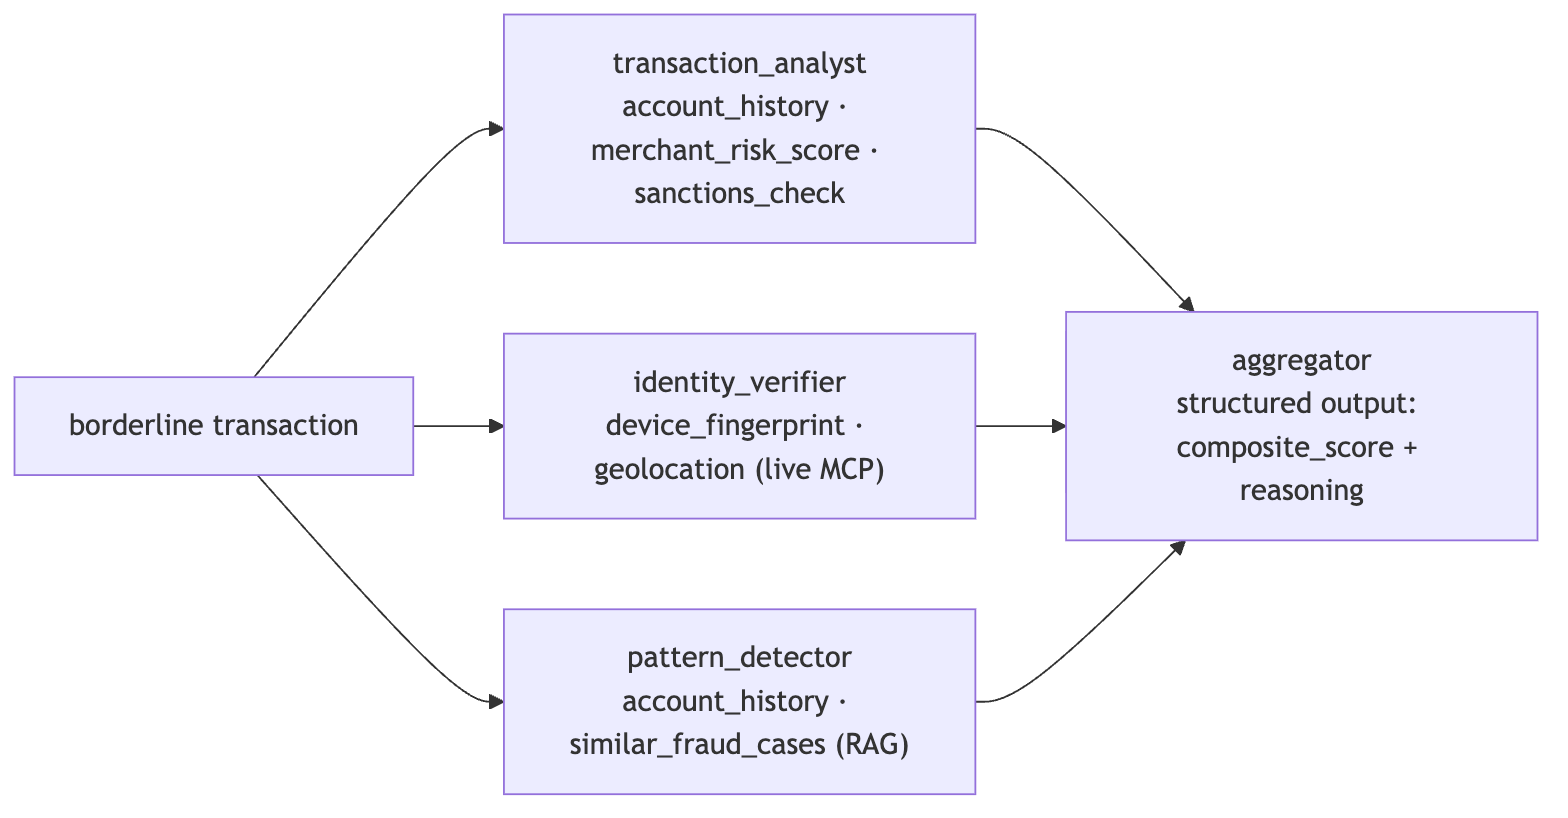

| Part | What it covers | Code |
|---|---|---|
| 1 | Setup | |
| 2 | Tools: what agents can call | `tools/llm_tools.py`, `tools/mock_apis.py` |
| 3 | RAG: searching past fraud cases | `tools/mock_apis.py: search_similar_fraud_cases()` |
| 4 | MCP: a live geolocation server | `mcp_server/geolocation_server.py`, `tools/mcp_geolocation.py` |
| 5 | ReAct: one agent, step by step | `core/specialist_factory.py` |
| 6 | All three specialists | `agents/` |
| 7 | The aggregator | `nodes/aggregator.py` |
| 8 | Recap and things to try | |

---
## Part 1 · Setup

### Setup
The next cell connects the notebook to the project. It gives this notebook **its own** database files in `.notebook_state/`, so nothing here touches the Streamlit app's data. It prints which LLM this run uses and whether its key is set (never the key itself). Set `SHOW_LIVE_LOGS = True` to see each node's live log line.

In [1]:
# ── Settings ────────────────────────────────────────────────────────────
# In Colab these two show as a checkbox and a dropdown (you can also type a model name).
SHOW_LIVE_LOGS = False  # @param {type: "boolean"}
LLM_MODEL = "gemini-3.5-flash"  # @param ["gemini-3.5-flash", "gemini-3.8-flash"] {allow-input: true}
# SHOW_LIVE_LOGS: print every node's live log line, like the terminal does.
# LLM_MODEL: model busy (503) or out of free quota (429)? Pick the other one, then
# Runtime > Restart session > Run all. Ignored when LLM_PROVIDER=openai.

# Setup: run from the repo root, and give this notebook its own database files in
# .notebook_state/ so it never touches the app's checkpoints.sqlite / account_memory.sqlite.
import logging
import os
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    # Google Colab: the notebook needs the whole repo (it imports core/, agents/, tools/),
    # so clone it and install the pinned packages on first run; later runs pull updates.
    import subprocess

    REPO = Path("/content/fintech-agent")
    if not REPO.exists():
        print("Colab: cloning the repo and installing packages (about a minute)...")
        subprocess.run(["git", "clone", "-q", "-b", "develop-gemini",
                        "https://github.com/iam-suraj-kumar/fintech-agent.git", str(REPO)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)
        print("Done. If a later cell fails to import, use Runtime > Restart session and run this cell again.")
    else:
        # Already cloned in this Colab session: pick up any fixes pushed since.
        # (Code already imported stays old until Runtime > Restart session.)
        pulled = subprocess.run(["git", "-C", str(REPO), "pull", "-q", "--ff-only"], capture_output=True, text=True)
        if pulled.returncode != 0:
            print("Colab: could not update the repo:", pulled.stderr.strip())
    os.chdir(REPO)
    try:
        from google.colab import userdata  # add GEMINI_API_KEY under the key icon (Secrets) in the sidebar

        os.environ.setdefault("GEMINI_API_KEY", userdata.get("GEMINI_API_KEY"))
    except Exception:
        print("No GEMINI_API_KEY secret found: notebooks 00 and 01 still work; 02-04 need it.")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
STATE_DIR = ROOT / ".notebook_state"
STATE_DIR.mkdir(exist_ok=True)
os.environ["CHECKPOINT_DB_PATH"] = str(STATE_DIR / "02_checkpoints.sqlite")
os.environ["MEMORY_DB_PATH"] = str(STATE_DIR / "02_memory.sqlite")
os.environ.setdefault("FASTMCP_LOG_LEVEL", "WARNING")  # quiet the MCP server subprocess
warnings.filterwarnings("ignore")

from dotenv import load_dotenv

load_dotenv(ROOT / ".env")  # never overrides the two database paths set above
if LLM_MODEL and (os.environ.get("LLM_PROVIDER") or "gemini").lower() == "gemini":
    os.environ["LLM_MODEL"] = LLM_MODEL  # the setting above wins over .env (Gemini models only)

import pandas as pd

pd.set_option("display.max_colwidth", None)  # show agent findings in full, not cut off with "..."


def trace_table(audit_log: list[dict]) -> pd.DataFrame:
    """One readable line per audit entry (entries have different fields, so a raw table is mostly blanks)."""
    def detail(e: dict) -> str:
        if e["kind"] == "tool_call":
            return f"calls {e['tool']}({e['args']})"
        if e["kind"] == "tool_result":
            return f"{e['tool']} returned {e['result']}"
        return str(e.get("text", ""))
    return pd.DataFrame([{"node": e.get("node", ""), "kind": e["kind"], "detail": detail(e)} for e in audit_log])

from html import escape

from langchain_core.runnables.graph import NodeStyles

# Explicit colours so the boxes read on both light and dark themes
# (LangGraph's default fills are pale but leave the text colour to the theme).
GRAPH_STYLES = NodeStyles(
    default="fill:#DCE6FA,stroke:#2459C2,stroke-width:1px,color:#15202E,line-height:1.2",
    first="fill:#2459C2,stroke:#2459C2,color:#FFFFFF",
    last="fill:#2F7A4A,stroke:#2F7A4A,color:#FFFFFF",
)


class _MermaidGraph:
    """Displays Mermaid code as a diagram. JupyterLab and VS Code draw Mermaid themselves;
    Colab doesn't, so there the browser draws it with Mermaid's JavaScript."""

    def __init__(self, source: str):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        html = (
            '<div style="background:#fff;padding:10px;border-radius:6px;display:inline-block">'
            '<pre class="mermaid">' + escape(self.source) + "</pre></div>"
            '<script type="module">'
            'import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11.4.1/dist/mermaid.esm.min.mjs";'
            'mermaid.initialize({startOnLoad: false, theme: "default"});'
            'await mermaid.run({querySelector: "pre.mermaid:not([data-processed])"});'
            "</script>"
        )
        if "google.colab" in sys.modules:
            return {"text/html": html}
        return {"text/markdown": "```mermaid\n" + self.source + "\n```"}


def show_graph(app):
    """Draw a compiled LangGraph graph."""
    return _MermaidGraph(app.get_graph().draw_mermaid(node_colors=GRAPH_STYLES))

import core.audit  # noqa: F401  (creates the "fraud_guard" live logger)
from core.llm import llm_model, llm_provider

logging.getLogger("fraud_guard").setLevel(logging.INFO if SHOW_LIVE_LOGS else logging.WARNING)
pd.set_option("display.max_colwidth", 160)
key = {"gemini": "GEMINI_API_KEY", "openai": "OPENAI_API_KEY"}.get(llm_provider(), "?")
print(f"LLM: {llm_provider()} / {llm_model()}   ({key} set: {'yes' if os.environ.get(key) else 'NO'})")

LLM: gemini / gemini-3.5-flash   (GEMINI_API_KEY set: yes)


---
## Part 2 · Tools: what agents can call

A **tool** is a Python function the LLM may ask to run. The `@tool` decorator turns its name, docstring and arguments into a description the model reads to decide when to call it. The model never runs code itself: it replies "call `account_history` with `acct_2002`", the framework runs the function, and the result goes back to the model.

In [2]:
from tools.llm_tools import account_history, device_fingerprint, merchant_risk_score, sanctions_check, similar_fraud_cases

pd.DataFrame([
    {"tool": t.name, "arguments": list(t.args), "description the LLM reads": t.description}
    for t in (account_history, merchant_risk_score, sanctions_check, device_fingerprint, similar_fraud_cases)
])

,tool,arguments,description the LLM reads
0,account_history,[account_id],"Look up an account's typical spending pattern: amount range, home country, and average transactions per week."
1,merchant_risk_score,[merchant_id],Look up a merchant's risk tier (low/medium/high) and numeric risk score.
2,sanctions_check,[beneficiary_name],Check whether a wire transfer beneficiary name appears on a sanctions watchlist.
3,device_fingerprint,[device_id],Look up whether a device ID is known for the account and how long ago it was first seen.
4,similar_fraud_cases,[description],Search a database of past confirmed fraud cases for ones textually similar to the given transaction description.


Calling tools directly, the way an agent would, for the two wire transfers. Note the sanctions check: `borderline_restart_demo` pays "Silk Road Holdings Ltd", which is on the mock watchlist.

In [3]:
from data.synthetic_transactions import SCENARIOS

for name in ("borderline_wire", "borderline_restart_demo"):
    t = SCENARIOS[name]
    print(f"===== {name}: ${t['amount']:,.0f} to {t['beneficiary_name']}")
    print("account_history     ", account_history.invoke({"account_id": t["account_id"]}))
    print("merchant_risk_score ", merchant_risk_score.invoke({"merchant_id": t["merchant_id"]}))
    print("device_fingerprint  ", device_fingerprint.invoke({"device_id": t["device_id"]}))
    print("sanctions_check     ", sanctions_check.invoke({"beneficiary_name": t["beneficiary_name"]}), "\n")

===== borderline_wire: $18,000 to Global Trading Partners LLC
account_history      {'typical_range': (500, 5000), 'country': 'US', 'avg_txn_count_per_week': 3}
merchant_risk_score  {'tier': 'high', 'score': 0.72}
device_fingerprint   {'known': True, 'first_seen_days_ago': 412}
sanctions_check      {'on_list': False, 'list_name': None, 'reason': None} 

===== borderline_restart_demo: $9,500 to Silk Road Holdings Ltd
account_history      {'typical_range': (500, 5000), 'country': 'US', 'avg_txn_count_per_week': 3}
merchant_risk_score  {'tier': 'high', 'score': 0.72}
device_fingerprint   {'known': False, 'first_seen_days_ago': 0}
sanctions_check      {'on_list': True, 'list_name': 'OFAC SDN (mock)', 'reason': 'shell entity linked to a prior enforcement action'} 



---
## Part 3 · RAG: searching past fraud cases

`similar_fraud_cases` is retrieval-augmented generation in miniature: a handful of past confirmed fraud cases are embedded into an in-memory **Chroma** vector store (using the embedding model of your provider), and the tool returns the 2 most similar to a description. The `pattern_detector` uses it to ask "have we seen this before?".

In [4]:
from tools.mock_apis import FRAUD_CASE_TEXTS

print(f"{len(FRAUD_CASE_TEXTS)} past cases in the store, e.g.:\n- {FRAUD_CASE_TEXTS[0]}\n")
query = "Large international wire transfer to a brand-new beneficiary from a business account"
for case in similar_fraud_cases.invoke({"description": query}):
    print("match:", case)

4 past cases in the store, e.g.:
- Card-not-present purchase for $2,340 at an electronics merchant the cardholder never used before, from a new device, immediately followed by a request to ship to a freight-forwarding address.

match: International wire transfer of $18,000 to a newly added beneficiary within 10 minutes of the beneficiary being added to the account.
match: Account login from a new device and new country followed within minutes by a large balance transfer.


---
## Part 4 · MCP: a live geolocation server

Everything else in the demo is mock data, but the `identity_verifier`'s geolocation is **real**. It comes from a separate **MCP server** (Model Context Protocol, a standard way to expose tools to AI apps):

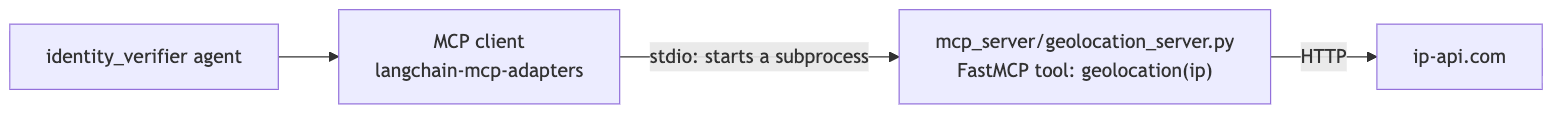

The first call starts the server process; `get_geolocation_tool()` wraps its async tool for the synchronous agents. Compare the live answer with the mock table triage used:

In [5]:
from tools.mcp_geolocation import get_geolocation_tool
from tools.mock_apis import get_geolocation

geo = get_geolocation_tool()
for name in ("impossible_travel", "borderline_wire"):
    t = SCENARIOS[name]
    print(f"{name}: mock {t['ip']} -> {get_geolocation(t['ip'])} | live {t['real_ip']} -> {geo.invoke({'ip': t['real_ip']})}")

impossible_travel: mock ip_ng_lagos -> {'country': 'NG', 'city': 'Lagos'} | live 105.112.0.1 -> {'country': 'NG', 'city': 'Ikenne', 'region': 'Ogun State', 'isp': 'Airtel Networks Limited'}
borderline_wire: mock ip_us_sf -> {'country': 'US', 'city': 'San Francisco'} | live 136.24.0.1 -> {'country': 'US', 'city': 'San Francisco', 'region': 'California', 'isp': 'Webpass Inc.'}


**What to notice:** the impossible-travel IP genuinely resolves to Nigeria, which is what makes the agent's write-up convincing rather than scripted.

---
## Part 5 · ReAct: one agent, step by step

Each specialist is a **ReAct agent** (reason + act), built with LangGraph's `create_react_agent`:

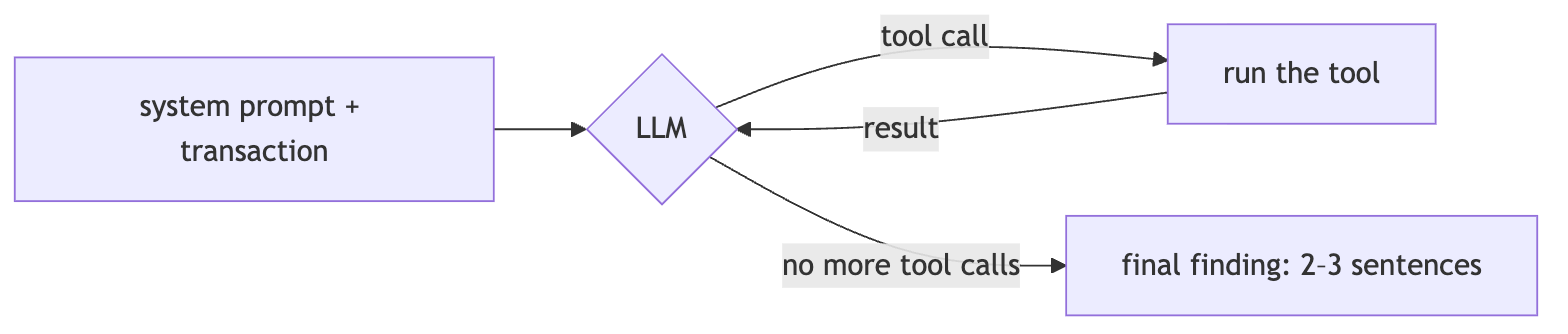

The LLM keeps choosing tools until it has enough, then writes its finding. `make_specialist_node()` wraps an agent into a graph node and records every tool call and result in the audit log. Running the transaction analyst on the wire to "Silk Road Holdings Ltd":

In [6]:
from agents.transaction_analyst import SYSTEM_PROMPT, transaction_analyst_node
from core.state import new_state

print("SYSTEM PROMPT:", SYSTEM_PROMPT, "\n")
update = transaction_analyst_node(new_state(SCENARIOS["borderline_restart_demo"]))

display(trace_table(update["audit_log"]))
print("FINDING:", update["analyst_findings"])

SYSTEM PROMPT: You are a transaction analyst investigating a potentially fraudulent financial transaction. Use the account history and merchant risk tools to check whether the amount and merchant are consistent with the account's typical behavior. If the transaction includes a beneficiary_name field, also run the sanctions_check tool on it - a match is a serious red flag and should dominate your assessment. Summarize your assessment in 2-3 sentences. 



,node,kind,detail
0,transaction_analyst,tool_call,calls account_history({'account_id': 'acct_2002'})
1,transaction_analyst,tool_call,calls merchant_risk_score({'merchant_id': 'merch_wire_intl_1'})
2,transaction_analyst,tool_call,calls sanctions_check({'beneficiary_name': 'Silk Road Holdings Ltd'})
3,transaction_analyst,tool_result,"account_history returned {'typical_range': [500, 5000], 'country': 'US', 'avg_txn_count_per_week': 3}"
4,transaction_analyst,tool_result,"merchant_risk_score returned {'tier': 'high', 'score': 0.72}"
5,transaction_analyst,tool_result,"sanctions_check returned {'on_list': True, 'list_name': 'OFAC SDN (mock)', 'reason': 'shell entity linked to a prior enforcement action'}"
6,transaction_analyst,summary,"This transaction presents severe fraud risks, highlighted by a direct match on the OFAC SDN sanctions watchlist for the beneficiary name 'Silk Road Holdings..."


FINDING: This transaction presents severe fraud risks, highlighted by a direct match on the OFAC SDN sanctions watchlist for the beneficiary name 'Silk Road Holdings Ltd'. Furthermore, the $9,500 wire transfer significantly exceeds the account's typical spending range of $500–$5,000 and involves a high-risk international merchant (risk score 0.72) via a new device. Given the sanctions hit and multiple anomalous indicators, this transaction should be immediately flagged and blocked for compliance review.


**What to notice:** the model decided on its own to call `sanctions_check` because the prompt says to when a beneficiary is present, and it leads its finding with the watchlist hit. Adding that skill took one more tool in a list; the graph did not change.

---
## Part 6 · All three specialists

Same factory, different prompts and tools. Each investigates one independent angle, which is why they can run in parallel in the graph. Here they run one after another on the $18,000 wire:

In [7]:
from agents.identity_verifier import identity_verifier_node
from agents.pattern_detector import pattern_detector_node

state = new_state(SCENARIOS["borderline_wire"])
findings = {}
for node, key in ((transaction_analyst_node, "analyst_findings"),
                  (identity_verifier_node, "identity_findings"),
                  (pattern_detector_node, "pattern_findings")):
    result = node(state)
    findings[key] = result[key]
    tools_used = [e["tool"] for e in result["audit_log"] if e["kind"] == "tool_call"]
    print(f"===== {key} (tools: {tools_used})\n{result[key]}\n")

===== analyst_findings (tools: ['account_history', 'merchant_risk_score', 'sanctions_check'])
This wire transfer of $18,000.00 significantly exceeds the account's typical spending range of $500 to $5,000 and involves a high-risk merchant with a risk score of 0.72. Although the beneficiary "Global Trading Partners LLC" cleared the sanctions watchlist check, the combination of an unusually large transaction amount and a high-risk international wire merchant presents a strong indication of potential fraud.

===== identity_findings (tools: ['device_fingerprint', 'geolocation'])
The device used for this transaction (`dev_known_1`) is a recognized, long-standing device first associated with the account 412 days ago. Additionally, geolocation analysis of the IP address `136.24.0.1` confirms a connection originating from San Francisco, California, aligning with typical domestic activity patterns. While the high transaction amount and new wire beneficiary warrant standard security checks, the d

---
## Part 7 · The aggregator

Three free-text opinions must become **one** number a router can compare. The aggregator asks the LLM for **structured output**: a Pydantic model with exactly two fields, so the reply is always parseable.

In [8]:
from nodes.aggregator import AGGREGATOR_THRESHOLD, AggregatorOutput, aggregator_node, route_after_aggregator
from nodes.triage import triage_node

print({name: field.description for name, field in AggregatorOutput.model_fields.items()}, "\n")
state = {**state, **triage_node(state), **findings}
result = aggregator_node(state)
print(f"composite_score = {result['composite_score']:.2f}  (human review at ≥ {AGGREGATOR_THRESHOLD})")
print("reasoning:", result["aggregate_reasoning"])
print("next node:", route_after_aggregator({**state, **result}))

{'composite_score': 'Overall fraud risk score from 0.0 (safe) to 1.0 (certain fraud)', 'reasoning': '2-4 sentence plain-English explanation combining all specialist findings'} 

composite_score = 0.68  (human review at ≥ 0.5)
reasoning: The transaction exhibits significant risk due to an $18,000 wire transfer that far exceeds the customer's typical spending limit and matches known fraud patterns involving newly added high-risk beneficiaries. However, the risk is partially mitigated by the use of a long-standing, trusted device operating from a familiar geographic location. Balancing the severe behavioral anomalies and pattern matches against the verified identity indicators results in a moderately high overall risk score.
next node: human_review


---
## Part 8 · Recap and things to try

**What happened:** tools gave the agents facts (mock services, a vector search over past fraud, and a live MCP server); each ReAct agent chose its own tool calls and wrote a short finding; the aggregator merged them into a structured score that decides whether a human must look.

**Try this**
- Run `identity_verifier_node` on `SCENARIOS["impossible_travel"]` and read how it uses the live Nigeria lookup.
- Search the fraud cases for "small test charges followed by a large purchase".
- Add a tool: write a `@tool` function and add it to one specialist's list in `agents/`. Nothing else changes.

**Next:** `03_full_graph.ipynb` runs all of this inside the real graph, including the pause for human review.